In [1]:
from tqdm.notebook import trange, tqdm
import numpy as np
from numpy import pi as π
import matplotlib.pyplot as plt
import firedrake
from firedrake import inner, grad, dx, ds, exp, min_value, max_value, Constant, derivative
import irksome
from icepack2 import model
import rasterio

In [2]:
import icepack

In [3]:
from scipy.spatial import cKDTree

In [ ]:
radius = Constant(12e3)
mesh = firedrake.UnitDiskMesh(4)
mesh.coordinates.dat.data[:] *= float(radius)

Next, we'll create some function spaces.
We'll use continuous linear finite elements for the basal elevation and discontinuous linear elements for the thickness.
In general, solving the mass balance equation for ice thickness tends to work much better with discontinuous elements.

In [ ]:
cg1 = firedrake.FiniteElement("CG", "triangle", 1)
S = firedrake.FunctionSpace(mesh, cg1)
dg1 = firedrake.FiniteElement("DG", "triangle", 1)
Q = firedrake.FunctionSpace(mesh, dg1)

Mt. Rainier is about 4km high.
We'll use a bed topography of the form $B\exp(-|x|^2/r^2)$, although this is actually a little unrealistic.

In [ ]:
x = firedrake.SpatialCoordinate(mesh)

B = Constant(4e3)
r_b = Constant(150e3 / (2 * π))
expr = B * exp(-inner(x, x) / r_b**2)
b = firedrake.Function(S).interpolate(expr)

In [ ]:
fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.set_title("Bed elevation")
colors = firedrake.tripcolor(b, axes=ax)
firedrake.tricontour(b, levels=[1600.0, 2100.0], colors="black", axes=ax)
fig.colorbar(colors);

According to Meier and Post, at 1600m elevation, the surface mass balance is about -8.7 m/yr of water equivalent, and the equilibrium line altitude (where surface mass balance is zero) is at about 2100m elevation, and that the SMB must average about 0.7 m/yr above the ELA for the glacier to be in balance.
We'll use these as rough guidelines; trying to be too exact about it gives an accumulation field with a really dramatic change near the ELA that results in generalized numerical mayhem.
When we define the SMB field, we clamp the values at the top and bottom in order to avoid producing unrealistic values.
Not also how we have to convert one of the SMB values from meters of water equivalent to meters of ice equivalent by multiplying by 0.917.

In [ ]:
z_measured = Constant(1600.0)
a_measured = Constant(-0.917 * 8.7)
a_top = Constant(0.7)
z_top = Constant(4e3)
δa_δz = (a_top - a_measured) / (z_top - z_measured)
a_max = Constant(0.7)

def smb(z):
    return min_value(a_max, a_measured + δa_δz * (z - z_measured))

We'll start with a very artificial initial guess for the thickness and evolve it toward equilibrium.

In [ ]:
r_h = Constant(5e3)
H = Constant(100.0)
expr = H * firedrake.max_value(0, 1 - inner(x, x) / r_h**2)
h_init = firedrake.Function(Q).interpolate(expr)

In [ ]:
fig, ax = plt.subplots()
ax.set_aspect("equal")
colors = firedrake.tripcolor(h_init, axes=ax)
fig.colorbar(colors);

We can then compute the initial surface elevation and mass balance.

In [ ]:
s = firedrake.Function(Q).interpolate(b + h_init)
a = firedrake.Function(Q).interpolate(smb(s))

In [ ]:
fig, ax = plt.subplots()
ax.set_aspect("equal")
colors = firedrake.tripcolor(a, vmin=-0.7, axes=ax)
fig.colorbar(colors);

## Overlord Data

In [4]:
mesh = firedrake.Mesh("Overlord_Data/overlord.msh")

In [5]:
cg1 = firedrake.FiniteElement("CG", "triangle", 1)
S = firedrake.FunctionSpace(mesh, cg1)
dg1 = firedrake.FiniteElement("DG", "triangle", 1)
Q = firedrake.FunctionSpace(mesh, dg1)

In [6]:
with rasterio.open("Overlord_Data/RGI60-02_00440_thk_masked.tif") as src:
    coords = mesh.coordinates.dat.data_ro
    thickness = np.array([v[0] for v in src.sample(coords[:, :2])])

    if src.nodata is not None:
        thickness[thickness == src.nodata] = np.nan

    thickness = np.nan_to_num(thickness, nan=0.0)

h_cg = firedrake.Function(S)
h_cg.dat.data[:] = thickness

h_init = firedrake.Function(Q).interpolate(h_cg)

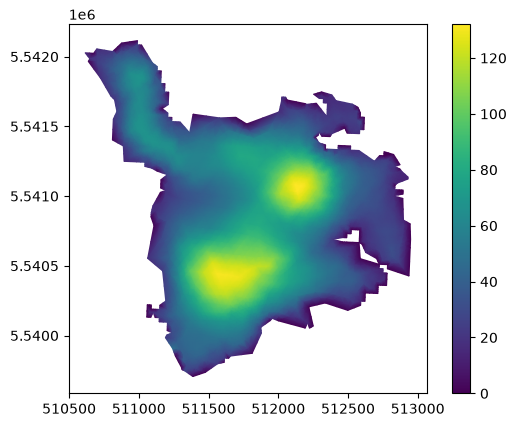

In [7]:
fig, ax = plt.subplots()
ax.set_aspect("equal")
colors = firedrake.tripcolor(h_init, axes=ax)
fig.colorbar(colors);

In [8]:
# fixing nan values for surface elev

with rasterio.open("Overlord_Data/2025_DEM_LiDAR_wide.tif") as src:
    coords = mesh.coordinates.dat.data_ro
    surface = np.array([v[0] for v in src.sample(coords[:, :2])], dtype=float)

    if src.nodata is not None:
        surface[surface == src.nodata] = np.nan
        
nan = np.isnan(surface)
valid = ~nan

if np.any(nan):
    tree = cKDTree(coords[valid, :2])
    _, idx = tree.query(coords[nan, :2])

    surface[nan] = surface[valid][idx]

s_cg = firedrake.Function(S)
s_cg.dat.data[:] = surface

s = firedrake.Function(Q).interpolate(s_cg)

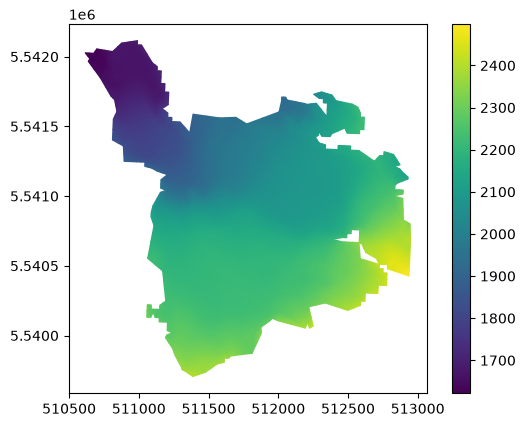

In [9]:
fig, ax = plt.subplots()
ax.set_aspect("equal")
colors = firedrake.tripcolor(s, axes=ax)
fig.colorbar(colors);

In [10]:
# h_init = firedrake.Function(Q).interpolate(thickness)
# s = firedrake.Function(Q).interpolate(surface)

In [11]:
with rasterio.open("Overlord_Data/LiDAR_vel_overlord.tif") as src:
    coords = mesh.coordinates.dat.data_ro
    observed_vel = np.array([v[0] for v in src.sample(coords[:, :2])])

    if src.nodata is not None:
        observed_vel[observed_vel == src.nodata] = np.nan

    observed_vel = np.nan_to_num(observed_vel, nan=0.0)

u0_cg = firedrake.Function(S)
u0_cg.dat.data[:] = observed_vel

u0_observed = firedrake.Function(Q).interpolate(u0_cg)

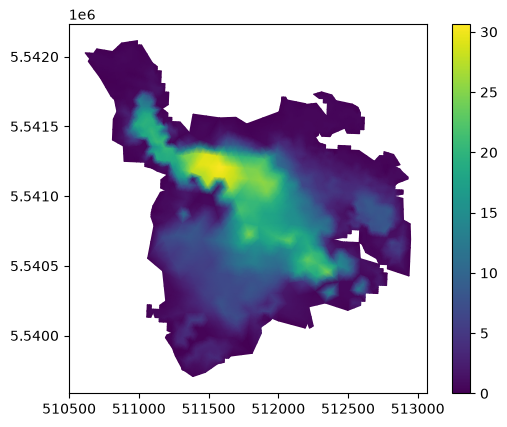

In [12]:
fig, ax = plt.subplots()
ax.set_aspect("equal")
colors = firedrake.tripcolor(u0_observed, axes=ax)
fig.colorbar(colors);

## Initial velocity computation

In order to calculate the material properties of the glacier, we'll assume that it's roughly temperate, which isn't too far off from the truth.

In [13]:
from icepack2.constants import gravity, ice_density, glen_flow_law
A = icepack.rate_factor(Constant(273.15))

To proceed, we have to make function spaces to represent the membrane and basal stresses and create a variable that stores the velocity and stresses.
Here we use piecewise constant finite elements for the membrane stresses.
In general, if you use $CG(k)$ elements for the velocity, you need to use $DG(k - 1)$ elements for the stresses.

In [14]:
V = firedrake.VectorFunctionSpace(mesh, cg1)

dg0 = firedrake.FiniteElement("DG", "triangle", 0)
Σ = firedrake.TensorFunctionSpace(mesh, dg0, symmetry=True)
Z = V * Σ * V * Q
z = firedrake.Function(Z)

This is a subtle but important point.
But we'll also want to regularize the momentum balance model a bit by pretending as if it were linear.
We chose some value of the ice fluidity $A$, which is fine, but remember that $A$ has units of strain rate $\times$ stress${}^{-n}$ where $n \approx 3$ is the Glen flow law exponent.
If we only change $n$ to 1 in the parts of the equation determining the constitutive relation but do nothing to $A$, the physical units that we use in the regularization will make no sense.
So what we do below is pick some arbitrary stress scale $\tau_c$, which here I'm taking to be 0.1 MPa or 100 kPa.
We're then choosing a strain rate scale $\dot\varepsilon_c$ so that $A = \dot\varepsilon_c \cdot\tau_c^{-n}$.
If we want to pretend like ice flow were linear, we could produce the right constitutive relation by then using the flow law coefficient $A' = \dot\varepsilon_c\cdot\tau_c^{-1}$ and all the units would make sense.

In [15]:
n = Constant(glen_flow_law)

τ_c = Constant(0.1)
ε_c = Constant(A * τ_c ** n)

Now we're at the really important part.
To make the SSA model effectively do SIA, what we need is that, in the sliding law
$$K|\tau|^{m - 1}\tau = -u,$$
we take
$$K = \frac{hA}{n + 2}.$$
Now in order to make our regularization approach work, we also define the sliding coefficient as
$$K = u_c / \tau_c^m$$
where $\tau_c$ is a reference stress and $u_c$ a reference speed.
We're using the same reference stress for the flow and sliding laws of $\tau_c = $ 100 kPa, so we can then compute the reference speed as $u_c = K\tau_c^m$.
We can then add more sliding on top of the effective deformation that we use to mimic SIA.
To add some extra real sliding, we've increased the critical speed $u_c$ by a factor of 100 m/yr.

In [16]:
u, M, τ, h = firedrake.split(z)

K = h * A / (n + 2)
# U_c = Constant(100.0)
u_c = K * τ_c ** n #+ U_c

In [17]:
glen_rheology = {
    "flow_law_exponent": n,
    "flow_law_coefficient": ε_c / τ_c ** n,
    "sliding_exponent": n,
    "sliding_coefficient": u_c / τ_c ** n,
}

α = firedrake.Constant(1e-4)
linear_rheology = {
    "flow_law_exponent": 1,
    "flow_law_coefficient": ε_c / τ_c,
    "sliding_exponent": 1,
    "sliding_coefficient": u_c / τ_c,
}

fields = {
    "velocity": u,
    "membrane_stress": M,
    "basal_stress": τ,
    "thickness": h,
    "surface": s,
}

Now we'll create the parameters that we need for the solver, including what quadrature degree and solution strategy to use.

In [18]:
degree = 1
qdegree = max(8, degree ** glen_flow_law)
pparams = {"form_compiler_parameters": {"quadrature_degree": qdegree}}

sparams = {
    "solver_parameters": {
        "snes_monitor": ":rainier-output-initial.log",
        "snes_type": "newtonls",
        "snes_max_it": 200,
        "snes_linesearch_type": "nleqerr",
        "ksp_type": "gmres",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    },
}

First, we'll do an initial solve with a linear rheology.
Then we'll gradually step the flow law exponent from 1.0 up to 3.0.

In [19]:
H = Constant(100.0)

In [20]:
from icepack2 import model
from icepack2.model.variational import momentum_balance, flow_law, friction_law

F_momentum = (
    momentum_balance(**fields)
    + firedrake.replace(flow_law(**fields, **glen_rheology), {h: H})
    + α * firedrake.replace(flow_law(**fields, **linear_rheology), {h: H})
    + friction_law(**fields, **glen_rheology)
    + α * friction_law(**fields, **linear_rheology)
)

v, N, σ, η = firedrake.TestFunctions(Z)
F_mass = (h - h_init) * η * dx

F = F_momentum + F_mass
momentum_problem = firedrake.NonlinearVariationalProblem(F, z, **pparams)
momentum_solver = firedrake.NonlinearVariationalSolver(momentum_problem, **sparams)

In [21]:
print("h_init NaNs:", np.isnan(h_init.dat.data_ro).sum())
print("s NaNs:", np.isnan(s.dat.data_ro).sum())

h_init NaNs: 0
s NaNs: 0


Now we can see our initial value of the velocity.
Note how it's a different magnitude but similar shape to the SIA velocity.

In [22]:
num_continuation_steps = 5
for exponent in np.linspace(1.0, 3.0, num_continuation_steps):
    n.assign(exponent)
    momentum_solver.solve()

In [26]:
thickness = 'Farinotti' # Farinotti, Millan, Maffezzoli
velocity = 'pixel' # pixel, ITSLive
DEM = 'LiDAR' # LiDAR, COP30
model = 'dualSSA_SIA'

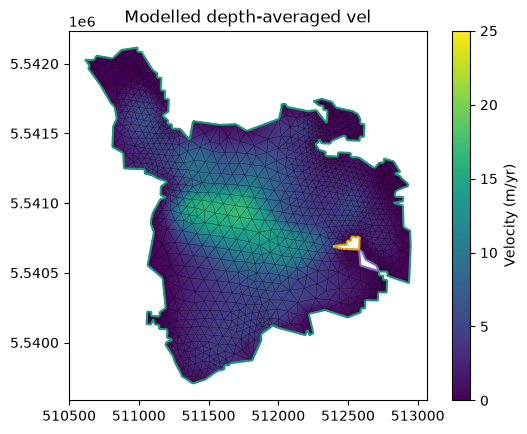

In [32]:
u_init, M_init, τ_init, h_init = z.subfunctions

fig, axes = plt.subplots()
axes.set_aspect("equal")
colors = firedrake.tripcolor(u_init, axes=axes,vmin=0,vmax=25)
firedrake.triplot(mesh, axes=axes, interior_kw={"linewidth": 0.1})
fig.colorbar(colors,label="Velocity (m/yr)");

plt.title('Modelled depth-averaged vel')

plt.savefig(f'Plots/Overlord_{thickness}_{velocity}_{DEM}_{model}_velocity_depthavg.png')

In [30]:
# stats
u_init_stats = firedrake.Function(Q)
u_init_stats.interpolate(firedrake.sqrt(u_init[0]**2 + u_init[1]**2))

print(np.min(u_init_stats.dat.data_ro))
print(np.max(u_init_stats.dat.data_ro))
print(np.mean(u_init_stats.dat.data_ro))

0.00011028422592488828
16.801211439382147
3.52089064412615


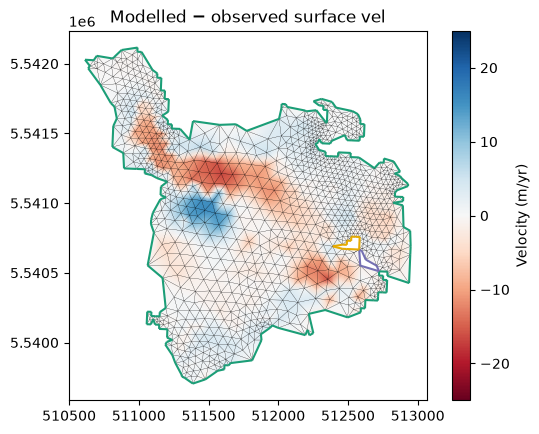

In [29]:
speed_model = firedrake.Function(Q)
speed_model.interpolate(
    firedrake.sqrt(u_init[0]**2 + u_init[1]**2) 
)

diff = firedrake.Function(Q)
diff.interpolate(speed_model - ((4.0 / 5.0) * u0_observed))

fig, axes = plt.subplots()
axes.set_aspect("equal")
colors = firedrake.tripcolor(diff, cmap="RdBu", axes=axes,vmin=-25,vmax=25)
firedrake.triplot(mesh, axes=axes, interior_kw={"linewidth": 0.1})
fig.colorbar(colors,label="Velocity (m/yr)");

plt.title('Modelled − observed surface vel')

plt.savefig(f'Plots/Overlord_{thickness}_{velocity}_{DEM}_{model}_velocity_diff.png')

In [ ]:
fig, axes = plt.subplots()
axes.set_aspect("equal")
axes.set_xlim((0, 10e3))
axes.set_ylim((0, 10e3))
colors = firedrake.tripcolor(u_init, axes=axes)
firedrake.triplot(mesh, axes=axes)
firedrake.tricontour(a, levels=[0, 1], colors="tab:orange", axes=axes)
fig.colorbar(colors);

Now make an even bigger function space, God help us all.
Pack in the initial values of the velocity, membrane stress, and basal stress that we computed before.

Next, form the momentum balance equation again.

In [ ]:
F_mass = model.mass_balance(thickness=h, velocity=u, accumulation=a)
F = F_momentum + F_mass

In [ ]:
tableau = irksome.BackwardEuler()
t = Constant(0.0)
dt = Constant(1.0 / 6)

lower = firedrake.Function(Z)
upper = firedrake.Function(Z)
lower.assign(-np.inf)
upper.assign(+np.inf)
lower.subfunctions[3].assign(0.0)
bounds = ("stage", lower, upper)

bparams = {
    "solver_parameters": {
        "snes_monitor": ":rainier-output-vi.log",
        "snes_type": "vinewtonrsls",
        "snes_max_it": 200,
        "ksp_type": "gmres",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    },
    "form_compiler_parameters": {"quadrature_degree": 6},
    "stage_type": "value",
    "basis_type": "Bernstein",
    "bounds": bounds,
}

solver = irksome.TimeStepper(F, tableau, t, dt, z, **bparams)

The good part: run the model for 500 years of simulation time.

In [ ]:
us = [z.subfunctions[0].copy(deepcopy=True)]
hs = [z.subfunctions[3].copy(deepcopy=True)]

final_time = 500.0
num_steps = int(final_time / float(dt))
for step in trange(num_steps):
    solver.advance()
    h = z.subfunctions[3]
    a.interpolate(smb(b + h))

    us.append(z.subfunctions[0].copy(deepcopy=True))
    hs.append(z.subfunctions[3].copy(deepcopy=True))

Now let's make a movie of the evolution towards steady state.
The contour shows the final value of the ELA.

In [ ]:
fig, axes = plt.subplots()
axes.set_aspect("equal")
axes.set_xlim((0, 10e3))
axes.set_ylim((0, 10e3))
colors = firedrake.tripcolor(hs[-1], num_sample_points=1, shading="flat", axes=axes)
firedrake.triplot(mesh, axes=axes)
firedrake.tricontour(a, levels=[0, 1], colors="tab:orange", axes=axes)
fig.colorbar(colors);

In [ ]:
u, M, τ, h = z.subfunctions

fig, axes = plt.subplots()
axes.set_aspect("equal")
axes.set_xlim((0, 10e3))
axes.set_ylim((0, 10e3))
colors = firedrake.tripcolor(us[-1], num_sample_points=1, shading="flat", axes=axes)
firedrake.triplot(mesh, axes=axes)
firedrake.tricontour(a, levels=[0, 1], colors="tab:orange", axes=axes)
fig.colorbar(colors);

In [ ]:
%%capture

fig, axes = plt.subplots()
axes.set_aspect("equal")
axes.set_xlim((0, 10e3))
axes.set_ylim((0, 10e3))
colors = firedrake.tripcolor(hs[0], vmax=130.0, num_sample_points=4, axes=axes)
fig.colorbar(colors);

In [ ]:
from matplotlib.animation import FuncAnimation

fn_plotter = firedrake.FunctionPlotter(mesh, num_sample_points=4)
def animate(h):
    colors.set_array(fn_plotter(h))

animation = FuncAnimation(fig, animate, tqdm(hs), interval=1e3/60)

In [ ]:
from IPython.display import HTML
HTML(animation.to_html5_video())

In [ ]:
volumes = [firedrake.assemble(h * dx) for h in hs]
fig, ax = plt.subplots()
ax.plot(volumes);